# **Riyadh Fly**

**Prepared by:** Sulaiman Allumaylim

## - Project Overview

This project focuses on analyzing flight movements at King Khalid International Airport in Riyadh. It aims to identify flight patterns, explore airline activity, and compare flight movements across different quarters using data analysis and visualization techniques.

## - Dataset Description

The *King Khalid International Airport Flights Dataset* contains flight records collected from multiple aviation and flight-tracking APIs. It includes information about airlines, aircraft, destinations, flight types, statuses, and scheduled movement times.

**Source:** [Kaggle – King Khalid International Airport Flights Dataset](https://www.kaggle.com/datasets/mohammedalsubaie/king-khalid-international-airport-flights-dataset/data)

## - Project Workflow

This notebook will cover data exploration, cleaning, and exploratory data analysis (EDA). It will visualize monthly flight movements, top destinations, airline activity, and peak flight times, and explore the possibility of predicting future flight activity.

##**Section 1: Data Loading & Structure**

This section covers importing libraries, loading the dataset, and examining its structure, data types, summary statistics, and missing values.

In [ ]:
# Import the libraries needed for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load the flight dataset from the Parquet file
df = pd.read_parquet("flights_RUH.parquet")

In [ ]:
# Display the first 5 rows to preview the dataset
df.head()

,flight_number,aircraft.model,aircraft.reg,aircraft.modeS,airline.name,airline.iata,airline.icao,status,flight_type,codeshareStatus,...,origin_airport_icao,origin_airport_iata,movement.terminal,movement.quality,destination_airport_icao,destination_airport_iata,destination_airport_name,movement.airport.timeZone,movement.scheduledTime.utc,movement.scheduledTime.local
0,PF 769,Airbus A320,None,None,Air Sial,PF,None,Unknown,departure,Unknown,...,OERK,RUH,2,[Basic],OPIS,ISB,Islamabad,Asia/Karachi,2025-03-14 21:01Z,2025-03-15 00:01+03:00
1,XY 333,Airbus A320 NEO,HZ-NS35,710DB9,flynas,XY,KNE,Unknown,departure,IsOperator,...,OERK,RUH,1,[Basic],VILK,LKO,Lucknow,Asia/Kolkata,2025-03-14 21:05Z,2025-03-15 00:05+03:00
2,QP 568,Boeing 737,None,None,Starlight Airline,QP,SLT,Unknown,departure,Unknown,...,OERK,RUH,3,[Basic],VABB,BOM,Mumbai,Asia/Kolkata,2025-03-14 21:05Z,2025-03-15 00:05+03:00
3,F3 161,Airbus A320,None,None,flyadeal,F3,FAD,Unknown,departure,Unknown,...,OERK,RUH,5,[Basic],OEJN,JED,Jeddah,Asia/Riyadh,2025-03-14 21:10Z,2025-03-15 00:10+03:00
4,KL 423,Airbus A330-300,None,None,KLM,KL,KLM,Unknown,departure,Unknown,...,OERK,RUH,1,[Basic],OEDF,DMM,Ad Dammam,Asia/Riyadh,2025-03-14 21:15Z,2025-03-15 00:15+03:00


In [ ]:
# Display the number of rows and columns
df.shape

(153308, 23)

In [ ]:
# Display column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153308 entries, 0 to 153307
Data columns (total 23 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   flight_number                 153308 non-null  object
 1   aircraft.model                153122 non-null  object
 2   aircraft.reg                  36234 non-null   object
 3   aircraft.modeS                45331 non-null   object
 4   airline.name                  153308 non-null  object
 5   airline.iata                  153294 non-null  object
 6   airline.icao                  152745 non-null  object
 7   status                        153308 non-null  object
 8   flight_type                   153308 non-null  object
 9   codeshareStatus               153308 non-null  object
 10  isCargo                       153308 non-null  bool  
 11  callSign                      45137 non-null   object
 12  origin_airport_name           153308 non-null  object
 13 

In [ ]:
# Display summary statistics for all columns
df.describe()

,flight_number,aircraft.model,aircraft.reg,aircraft.modeS,airline.name,airline.iata,airline.icao,status,flight_type,codeshareStatus,...,origin_airport_icao,origin_airport_iata,movement.terminal,movement.quality,destination_airport_icao,destination_airport_iata,destination_airport_name,movement.airport.timeZone,movement.scheduledTime.utc,movement.scheduledTime.local
count,153308,153122,36234,45331,153308,153294,152745,153308,153308,153308,...,153308,153308,152458,153308,149202,149202,153308,149202,153308,153308
unique,1369,48,1431,1612,68,62,63,5,2,2,...,1,1,5,1,120,120,128,48,54364,54364
top,LH 622,Airbus A320,HZ-NS34,717CEA,Saudi Arabian,SV,SVA,Unknown,departure,Unknown,...,OERK,RUH,5,[Basic],OEJN,JED,Jeddah,Asia/Riyadh,2025-09-04 13:00Z,2025-09-04 16:00+03:00
freq,403,59394,391,390,60886,60886,60886,128618,78252,104554,...,153308,153308,80729,153308,27444,27444,27938,79413,16,16


In [ ]:
# Count missing values in each column
df.isnull().sum()

,0
flight_number,0
aircraft.model,186
aircraft.reg,117074
aircraft.modeS,107977
airline.name,0
airline.iata,14
airline.icao,563
status,0
flight_type,0
codeshareStatus,0


##**Section 2: Data Cleaning & Preprocessing**

This section focuses on handling missing values, duplicate records, and data type issues to prepare the dataset for the project's analysis and visualization requirements.

In [ ]:
# Select only the columns relevant to the flight analysis and dashboard,
# removing unnecessary columns to keep the dataset focused on the project only
columns_to_keep = [
    "flight_number",
    "aircraft.model",
    "airline.name",
    "status",
    "flight_type",
    "origin_airport_name",
    "movement.terminal",
    "destination_airport_name",
    "movement.airport.timeZone",
    "movement.scheduledTime.local"
]

# Select the required columns
df = df[columns_to_keep].copy()

In [ ]:
df.head()

,flight_number,aircraft.model,airline.name,status,flight_type,origin_airport_name,movement.terminal,destination_airport_name,movement.airport.timeZone,movement.scheduledTime.local
0,PF 769,Airbus A320,Air Sial,Unknown,departure,Riyadh,2,Islamabad,Asia/Karachi,2025-03-15 00:01+03:00
1,XY 333,Airbus A320 NEO,flynas,Unknown,departure,Riyadh,1,Lucknow,Asia/Kolkata,2025-03-15 00:05+03:00
2,QP 568,Boeing 737,Starlight Airline,Unknown,departure,Riyadh,3,Mumbai,Asia/Kolkata,2025-03-15 00:05+03:00
3,F3 161,Airbus A320,flyadeal,Unknown,departure,Riyadh,5,Jeddah,Asia/Riyadh,2025-03-15 00:10+03:00
4,KL 423,Airbus A330-300,KLM,Unknown,departure,Riyadh,1,Ad Dammam,Asia/Riyadh,2025-03-15 00:15+03:00


Since this project focuses on comparing flight activity between Q2 and Q3 of 2025, records from other months are not needed. The following steps convert the scheduled movement time to datetime format, filter the dataset to keep only the required months (April–September 2025), and verify the results.

In [ ]:
# Convert the scheduled movement time column to datetime
df["movement.scheduledTime.local"] = pd.to_datetime(
    df["movement.scheduledTime.local"]
)

In [ ]:
# Keep flight records from Q2 and Q3 of 2025
df = df[
    (df["movement.scheduledTime.local"] >= "2025-04-01") &
    (df["movement.scheduledTime.local"] < "2025-10-01")
].copy()

In [ ]:
# Display the date range and number of records after filtering
print("Number of records:", len(df))
print("First date:", df["movement.scheduledTime.local"].min())
print("Last date:", df["movement.scheduledTime.local"].max())

Number of records: 135813
First date: 2025-04-01 00:01:00+03:00
Last date: 2025-09-30 23:55:00+03:00


The dataset initially contained 153,308 flight records. After filtering out months outside Q2 and Q3 of 2025, the dataset was reduced to 135,813 records, a decrease of 17,495 records. This ensures that the analysis focuses only on the six months required for the project.

In [ ]:
# Check the number of missing values in each column
df.isnull().sum()

,0
flight_number,0
aircraft.model,0
airline.name,0
status,0
flight_type,0
origin_airport_name,0
movement.terminal,745
destination_airport_name,0
movement.airport.timeZone,3691
movement.scheduledTime.local,0


The dataset contains missing values in the movement.terminal and movement.airport.timeZone columns. These columns are not essential for the current analysis, so the missing values will not be handled at this stage. However, both columns will be retained in case they are useful for future analysis or additional dashboard features.

In [ ]:
# Remove duplicate rows and compare the dataset size before and after cleaning

# Count the records before removing duplicates
records_before = len(df)

# Remove duplicate rows while keeping the first occurrence
df = df.drop_duplicates().copy()

# Count the records after removing duplicates
records_after = len(df)

# Display the results
print("Records before removing duplicates:", records_before)
print("Records after removing duplicates:", records_after)
print("Duplicate records removed:", records_before - records_after)

Records before removing duplicates: 135813
Records after removing duplicates: 135555
Duplicate records removed: 258


In [ ]:
# Split the scheduled movement time into separate date and time columns
df["scheduled_date"] = df["movement.scheduledTime.local"].dt.date
df["scheduled_time"] = df["movement.scheduledTime.local"].dt.strftime("%H:%M:%S")

In [ ]:
# Display the new date and time columns
df[["movement.scheduledTime.local", "scheduled_date", "scheduled_time"]].head(10)

,movement.scheduledTime.local,scheduled_date,scheduled_time
5528,2025-04-01 00:01:00+03:00,2025-04-01,00:01:00
5529,2025-04-01 00:05:00+03:00,2025-04-01,00:05:00
5530,2025-04-01 00:05:00+03:00,2025-04-01,00:05:00
5531,2025-04-01 00:15:00+03:00,2025-04-01,00:15:00
5532,2025-04-01 00:20:00+03:00,2025-04-01,00:20:00
5533,2025-04-01 00:30:00+03:00,2025-04-01,00:30:00
5534,2025-04-01 00:30:00+03:00,2025-04-01,00:30:00
5535,2025-04-01 00:35:00+03:00,2025-04-01,00:35:00
5536,2025-04-01 00:35:00+03:00,2025-04-01,00:35:00
5537,2025-04-01 00:45:00+03:00,2025-04-01,00:45:00


In [ ]:
# Rename columns to clear and consistent names for analysis and dashboard development
df = df.rename(columns={
    "flight_number": "flight_number",
    "aircraft.model": "aircraft_model",
    "airline.name": "airline_name",
    "status": "flight_status",
    "flight_type": "flight_type",
    "origin_airport_name": "origin_airport",
    "movement.terminal": "terminal",
    "destination_airport_name": "destination_airport",
    "movement.airport.timeZone": "airport_timezone",
    "movement.scheduledTime.local": "scheduled_datetime",
    "scheduled_date": "scheduled_date",
    "scheduled_time": "scheduled_time"
})

In [ ]:
# Create a separate dataset for EDA by excluding canceled flights
# and removing columns that are not needed for the current analysis

# Exclude canceled and uncertain-cancellation flights
df_eda = df[
    ~df["flight_status"].isin(["Canceled", "CanceledUncertain"])
].copy()

# Remove columns that are not needed for the current analysis
columns_to_drop = [
    "flight_status",
    "origin_airport",
    "terminal",
    "airport_timezone",
    "scheduled_datetime"
]

df_eda = df_eda.drop(columns=columns_to_drop)

# Display the first 5 rows of the new dataset
df_eda.head()

,flight_number,aircraft_model,airline_name,flight_type,destination_airport,scheduled_date,scheduled_time
5528,SV 8849,Airbus A320,Saudi Arabian,departure,Neyran,2025-04-01,00:01:00
5529,XY 333,Airbus A320 NEO,flynas,departure,Lucknow,2025-04-01,00:05:00
5530,CA 790,Boeing 777-200,Air China,departure,Beijing,2025-04-01,00:05:00
5531,F3 161,Airbus A320 NEO,flyadeal,departure,Jeddah,2025-04-01,00:15:00
5532,XY 61,Airbus A320,flynas,departure,Jeddah,2025-04-01,00:20:00


In [ ]:
df.head()

,flight_number,aircraft_model,airline_name,flight_status,flight_type,origin_airport,terminal,destination_airport,airport_timezone,scheduled_datetime,scheduled_date,scheduled_time
5528,SV 8849,Airbus A320,Saudi Arabian,Unknown,departure,Riyadh,5,Neyran,Asia/Riyadh,2025-04-01 00:01:00+03:00,2025-04-01,00:01:00
5529,XY 333,Airbus A320 NEO,flynas,Unknown,departure,Riyadh,1,Lucknow,Asia/Kolkata,2025-04-01 00:05:00+03:00,2025-04-01,00:05:00
5530,CA 790,Boeing 777-200,Air China,Expected,departure,Riyadh,1,Beijing,Asia/Shanghai,2025-04-01 00:05:00+03:00,2025-04-01,00:05:00
5531,F3 161,Airbus A320 NEO,flyadeal,Unknown,departure,Riyadh,5,Jeddah,Asia/Riyadh,2025-04-01 00:15:00+03:00,2025-04-01,00:15:00
5532,XY 61,Airbus A320,flynas,Unknown,departure,Riyadh,5,Jeddah,Asia/Riyadh,2025-04-01 00:20:00+03:00,2025-04-01,00:20:00


In [ ]:
# Save the cleaned EDA dataset to a CSV file
df_eda.to_csv("Riyadh_Fly_EDA_Cleaned.csv", index=False)

##**Section 3: Exploratory Data Analysis (EDA)**

This section explores the dataset to identify patterns and trends in flight activity.
It includes univariate, bivariate, and multivariate analysis using different visualization techniques.
The analysis focuses on understanding flight activity during Q2 and Q3 of 2025.

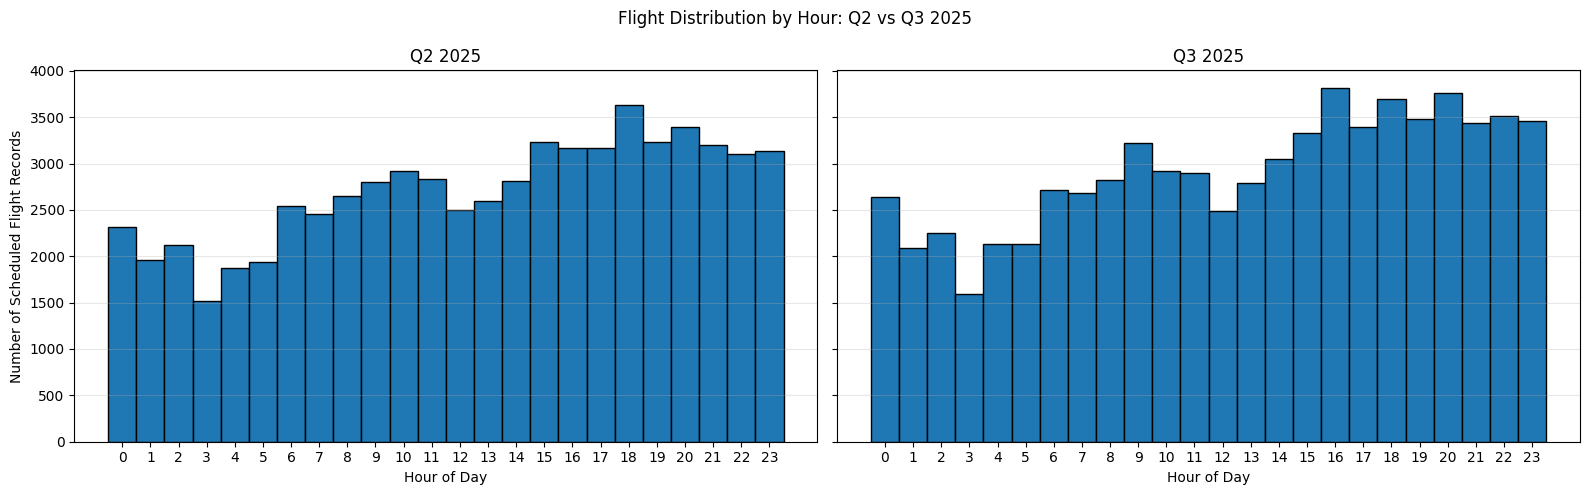

In [ ]:
# Histograms
# Univariate Analysis: Flight Distribution by Hour

# Convert scheduled_date to datetime format
df_eda["scheduled_date"] = pd.to_datetime(df_eda["scheduled_date"])

# Extract the scheduled hour (0-23) from scheduled_time
df_eda["scheduled_hour"] = pd.to_datetime(
    df_eda["scheduled_time"], format="%H:%M:%S"
).dt.hour

# Define Q2 and Q3 date ranges
q2 = df_eda[
    (df_eda["scheduled_date"] >= "2025-04-01") &
    (df_eda["scheduled_date"] < "2025-07-01")
]

q3 = df_eda[
    (df_eda["scheduled_date"] >= "2025-07-01") &
    (df_eda["scheduled_date"] < "2025-10-01")
]

# Create two histograms for comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
fig.suptitle("Flight Distribution by Hour: Q2 vs Q3 2025")

# Q2 Histogram
axes[0].hist(q2["scheduled_hour"], bins=np.arange(25) - 0.5,
             edgecolor="black")
axes[0].set_title("Q2 2025")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Number of Scheduled Flight Records")
axes[0].set_xticks(range(24))
axes[0].grid(axis="y", alpha=0.3)

# Q3 Histogram
axes[1].hist(q3["scheduled_hour"], bins=np.arange(25) - 0.5,
             edgecolor="black")
axes[1].set_title("Q3 2025")
axes[1].set_xlabel("Hour of Day")
axes[1].set_xticks(range(24))
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Question:** Do peak flight hours differ between Q2 and Q3 of 2025?

**Insight:** Both quarters show higher flight activity during the afternoon and evening. Q2 reaches its peak around 18:00, while Q3 peaks around 16:00. Flight activity is relatively low around 03:00 in both quarters.

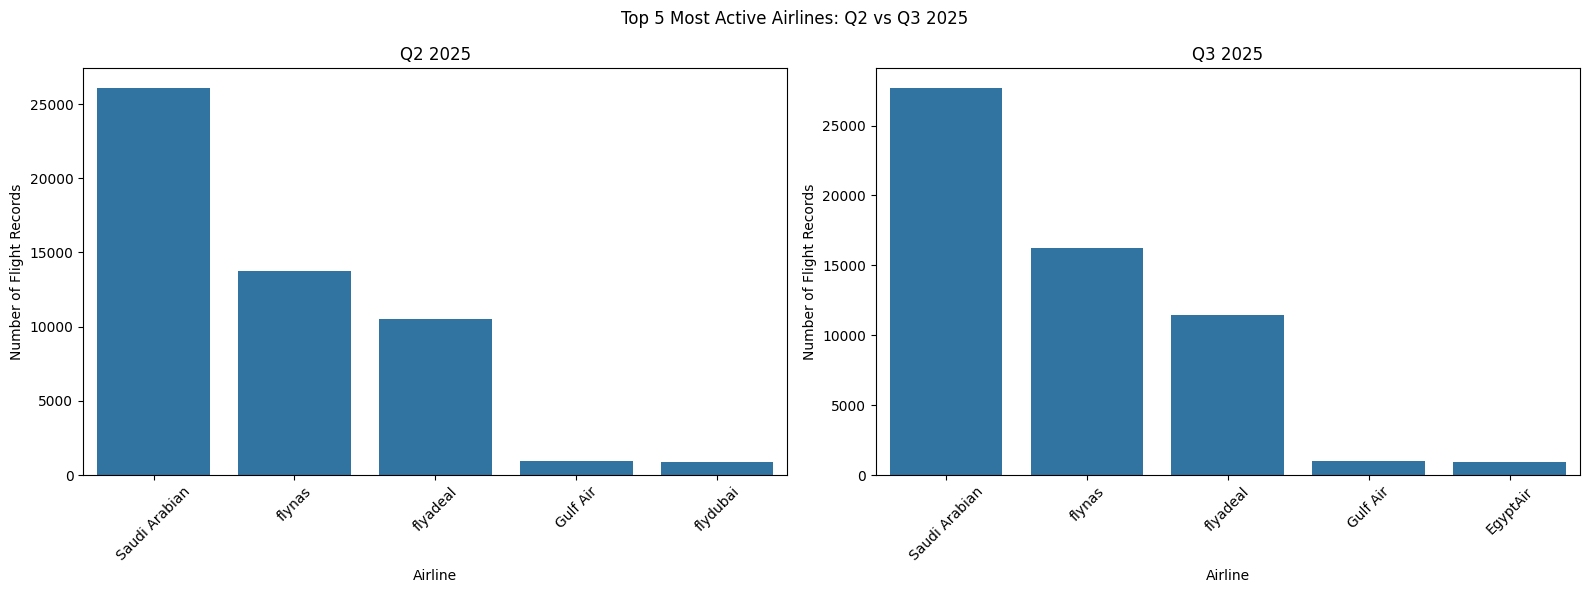

In [ ]:
# Countplots
# Univariate Analysis: Top 5 Most Active Airlines

# Identify the top 5 airlines in each quarter
q2_top5 = q2["airline_name"].value_counts().head(5).index
q3_top5 = q3["airline_name"].value_counts().head(5).index

# Filter the data to include only the top 5 airlines
q2_top5_data = q2[q2["airline_name"].isin(q2_top5)]
q3_top5_data = q3[q3["airline_name"].isin(q3_top5)]

# Create two vertical countplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Top 5 Most Active Airlines: Q2 vs Q3 2025")

# Q2 Countplot
sns.countplot(
    data=q2_top5_data,
    x="airline_name",
    order=q2_top5_data["airline_name"].value_counts().index,
    ax=axes[0]
)
axes[0].set_title("Q2 2025")
axes[0].set_xlabel("Airline")
axes[0].set_ylabel("Number of Flight Records")
axes[0].tick_params(axis="x", rotation=45)

# Q3 Countplot
sns.countplot(
    data=q3_top5_data,
    x="airline_name",
    order=q3_top5_data["airline_name"].value_counts().index,
    ax=axes[1]
)
axes[1].set_title("Q3 2025")
axes[1].set_xlabel("Airline")
axes[1].set_ylabel("Number of Flight Records")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Question:** Which airlines had the highest number of flight records in Q2 and Q3 of 2025?

**Insight:** Saudi Arabian Airlines had the highest number of flight records in both quarters, followed by flynas and flyadeal. The top three airlines remained consistent across Q2 and Q3, while the fifth-ranked airline changed from flydubai in Q2 to EgyptAir in Q3.

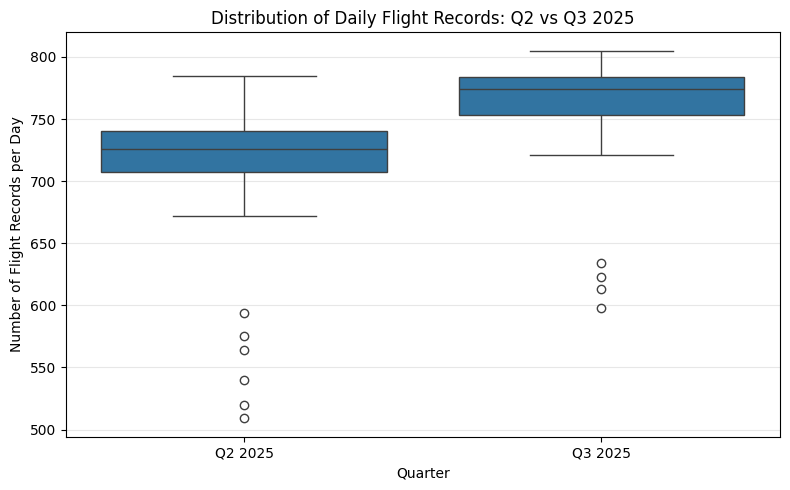

In [ ]:
# Boxplots
# Univariate Analysis: Daily Flight Records

# Count flight records for each day
daily_flights = df_eda.groupby("scheduled_date").size().reset_index(name="flight_count")

# Assign each date to its quarter
daily_flights["quarter"] = np.where(
    daily_flights["scheduled_date"] < "2025-07-01",
    "Q2 2025",
    "Q3 2025"
)

# Create a boxplot to compare daily flight records
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=daily_flights,
    x="quarter",
    y="flight_count",
    order=["Q2 2025", "Q3 2025"]
)

plt.title("Distribution of Daily Flight Records: Q2 vs Q3 2025")
plt.xlabel("Quarter")
plt.ylabel("Number of Flight Records per Day")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Question:** Does daily flight activity vary between Q2 and Q3 of 2025?

**Insight:** Q3 had a higher median number of daily flight records than Q2. Daily flight counts were more concentrated in Q3, while both quarters had some unusually low-count days.

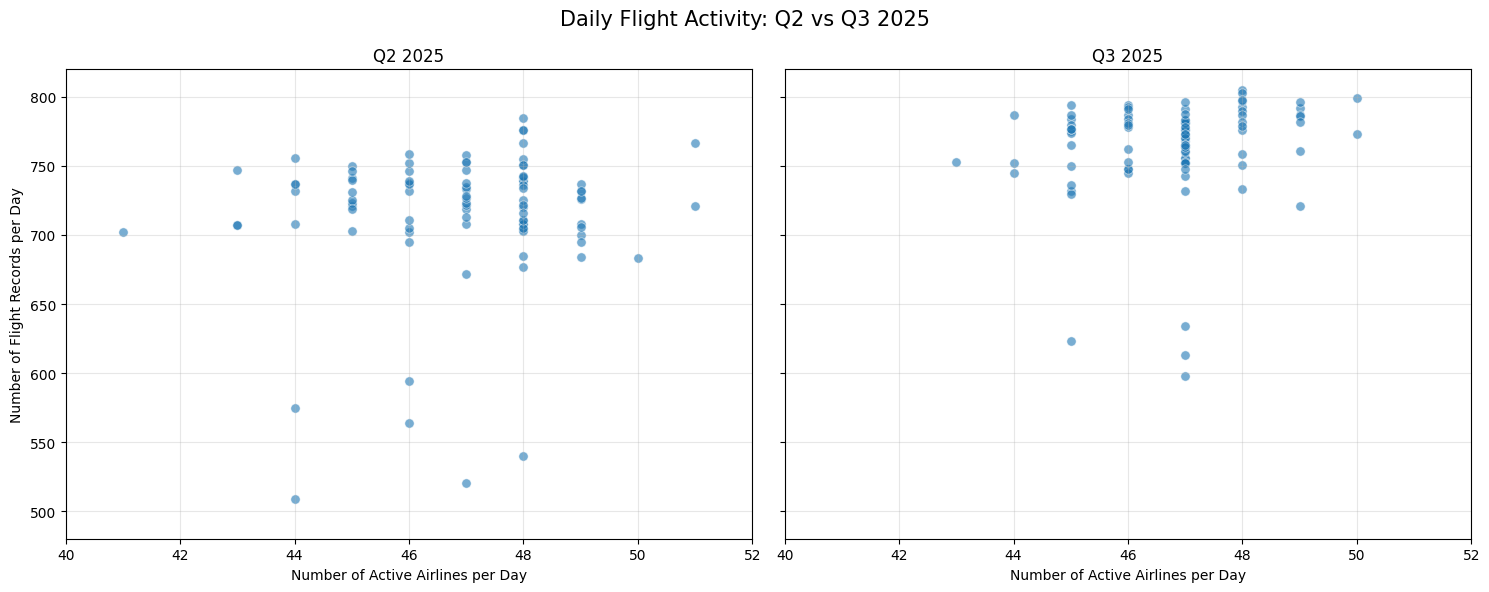

In [ ]:
# Scatter plots
# Bivariate Analysis: Daily Flight Activity

# Calculate daily flight records and active airlines
daily_activity = df_eda.groupby("scheduled_date").agg(
    flight_count=("flight_number", "size"),
    active_airlines=("airline_name", "nunique")
).reset_index()

# Separate Q2 and Q3 data
q2_daily = daily_activity[
    (daily_activity["scheduled_date"] >= "2025-04-01") &
    (daily_activity["scheduled_date"] < "2025-07-01")
]

q3_daily = daily_activity[
    (daily_activity["scheduled_date"] >= "2025-07-01") &
    (daily_activity["scheduled_date"] < "2025-10-01")
]

# Create two scatter plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

fig.suptitle("Daily Flight Activity: Q2 vs Q3 2025", fontsize=15)

# Q2 Scatter Plot
sns.scatterplot(
    data=q2_daily,
    x="active_airlines",
    y="flight_count",
    ax=axes[0],
    alpha=0.6,
    s=45
)

axes[0].set_title("Q2 2025")
axes[0].set_xlabel("Number of Active Airlines per Day")
axes[0].set_ylabel("Number of Flight Records per Day")
axes[0].grid(alpha=0.3)

# Q3 Scatter Plot
sns.scatterplot(
    data=q3_daily,
    x="active_airlines",
    y="flight_count",
    ax=axes[1],
    alpha=0.6,
    s=45
)

axes[1].set_title("Q3 2025")
axes[1].set_xlabel("Number of Active Airlines per Day")
axes[1].set_ylabel("Number of Flight Records per Day")
axes[1].grid(alpha=0.3)

# Set axis limits and ticks
for ax in axes:
    ax.set_xlim(40, 52)
    ax.set_ylim(480, 820)
    ax.set_xticks(range(40, 53, 2))
    ax.set_yticks(range(500, 821, 50))

plt.tight_layout()
plt.show()

**Question:** Do days with more active airlines tend to have more flight records?

**Insight:** Most days recorded approximately 700–800 flight records. However, the scatter plot does not show a clear pattern indicating that having more active airlines necessarily leads to more flight records.

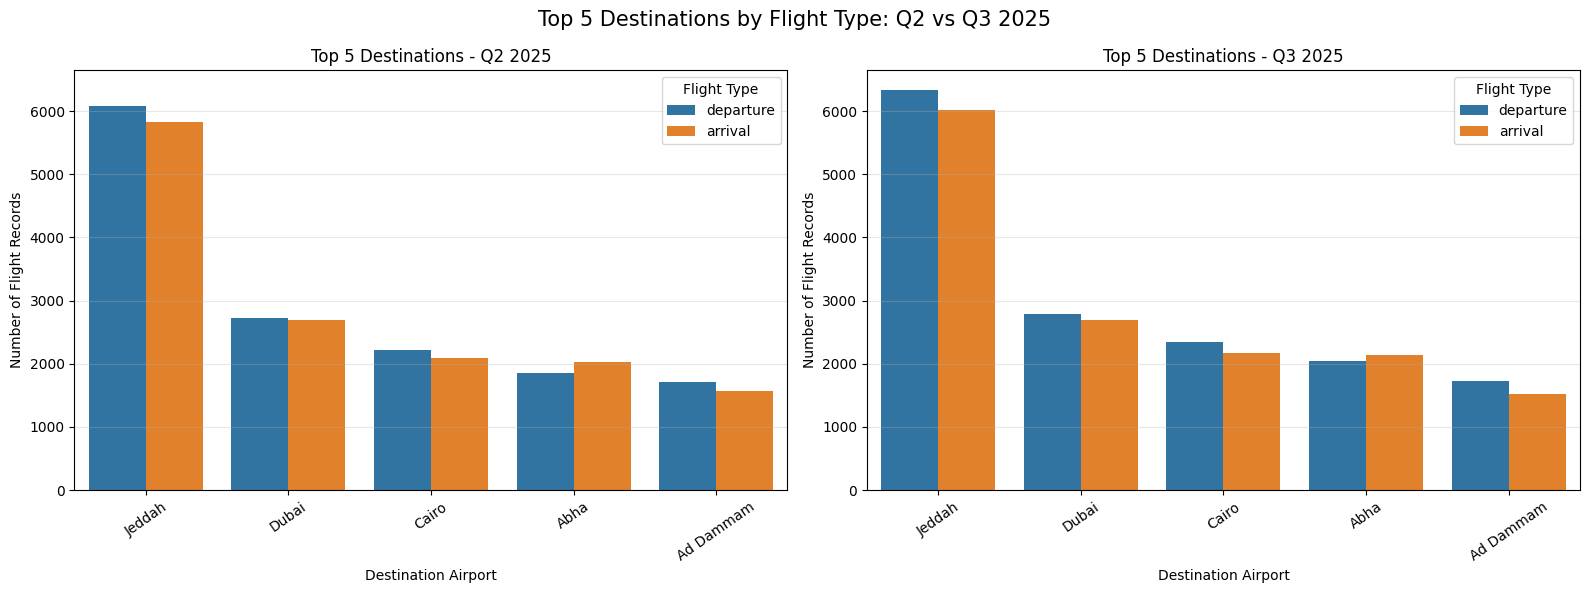

In [ ]:
# Bar plots
# Multivariate Analysis: Top 5 Destinations by Flight Type

# Filter Q2 and Q3 records
df_q2 = df_eda[
    (df_eda["scheduled_date"] >= "2025-04-01") &
    (df_eda["scheduled_date"] < "2025-07-01")
].copy()

df_q3 = df_eda[
    (df_eda["scheduled_date"] >= "2025-07-01") &
    (df_eda["scheduled_date"] < "2025-10-01")
].copy()

# Identify the top 5 destinations in each quarter
top5_q2 = df_q2["destination_airport"].value_counts().head(5).index
top5_q3 = df_q3["destination_airport"].value_counts().head(5).index

# Keep only the top 5 destinations
df_q2_top5 = df_q2[
    df_q2["destination_airport"].isin(top5_q2)
]

df_q3_top5 = df_q3[
    df_q3["destination_airport"].isin(top5_q3)
]

# Create two side-by-side bar plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Q2 plot
sns.countplot(
    data=df_q2_top5,
    x="destination_airport",
    hue="flight_type",
    order=top5_q2,
    ax=axes[0]
)

axes[0].set_title("Top 5 Destinations - Q2 2025")
axes[0].set_xlabel("Destination Airport")
axes[0].set_ylabel("Number of Flight Records")
axes[0].tick_params(axis="x", rotation=35)
axes[0].legend(title="Flight Type")
axes[0].grid(axis="y", alpha=0.3)

# Q3 plot
sns.countplot(
    data=df_q3_top5,
    x="destination_airport",
    hue="flight_type",
    order=top5_q3,
    ax=axes[1]
)

axes[1].set_title("Top 5 Destinations - Q3 2025")
axes[1].set_xlabel("Destination Airport")
axes[1].set_ylabel("Number of Flight Records")
axes[1].tick_params(axis="x", rotation=35)
axes[1].legend(title="Flight Type")
axes[1].grid(axis="y", alpha=0.3)

# Use the same y-axis scale for both plots
max_count = max(
    axes[0].get_ylim()[1],
    axes[1].get_ylim()[1]
)

axes[0].set_ylim(0, max_count)
axes[1].set_ylim(0, max_count)

fig.suptitle(
    "Top 5 Destinations by Flight Type: Q2 vs Q3 2025",
    fontsize=15
)

plt.tight_layout()
plt.show()

**Question:** Which destinations had the highest number of flight records, and how were they ranked by flight type?

**Insight:** Jeddah ranked first, followed by Dubai, Cairo, Abha, and Ad Dammam. Departures generally outnumbered arrivals, except in Abha. The overall ranking and flight patterns remained similar in Q2 and Q3 of 2025.

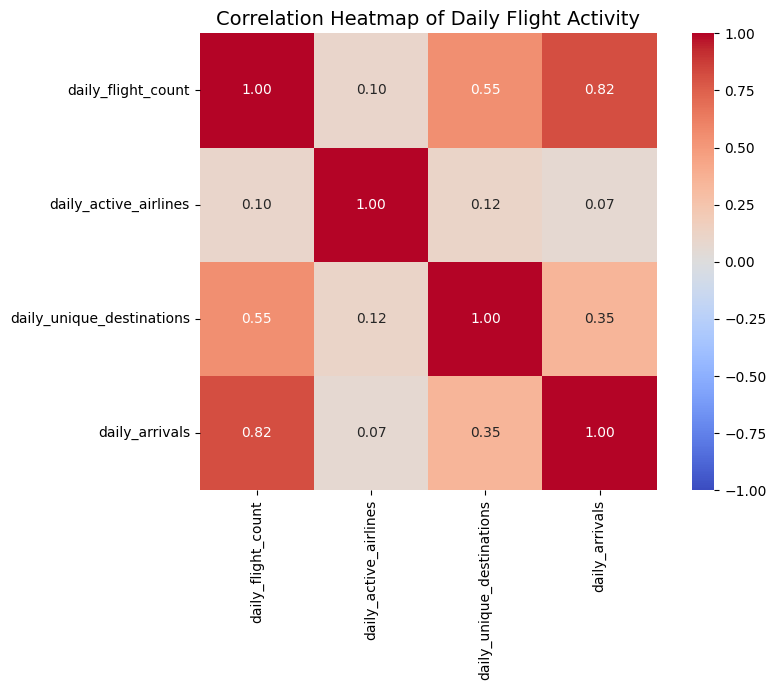

In [ ]:
# Correlation Heatmap: Daily Flight Activity

# Filter Q2 and Q3 of 2025
df_q2_q3 = df_eda[
    (df_eda["scheduled_date"] >= "2025-04-01") &
    (df_eda["scheduled_date"] < "2025-10-01")
].copy()

# Calculate daily flight activity metrics
daily_data = (
    df_q2_q3.groupby("scheduled_date")
    .agg(
        daily_flight_count=("flight_number", "size"),
        daily_active_airlines=("airline_name", "nunique"),
        daily_unique_destinations=("destination_airport", "nunique"),
        daily_arrivals=("flight_type", lambda x: (x == "arrival").sum())
    )
    .reset_index()
)

# Select variables for correlation analysis
corr_data = daily_data[
    [
        "daily_flight_count",
        "daily_active_airlines",
        "daily_unique_destinations",
        "daily_arrivals"
    ]
]

# Calculate correlation matrix
corr_matrix = corr_data.corr()

# Plot correlation heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap of Daily Flight Activity", fontsize=14)
plt.tight_layout()
plt.show()

**Question:** How are daily flight records related to airlines, destinations, and arrivals?

**Insight:** Daily flight records showed a strong positive correlation with arrivals (0.82) and a moderate correlation with unique destinations (0.55). The relationship with active airlines was weak (0.10).

##**Section 4: Predictive Modeling**

This section uses Machine Learning to forecast flight activity during Q4 of 2025 based on historical data from Q2 and Q3. It applies a Random Forest Regressor to predict monthly flight volumes and identify expected busiest hours, alongside historical-based estimates for destinations and airlines.

MAE: 20.87
RMSE: 23.87

Q4 2025 Flight Forecast:
October     23144
November    22413
December    23155
Name: predicted, dtype: int64
Q4 Total: 68712


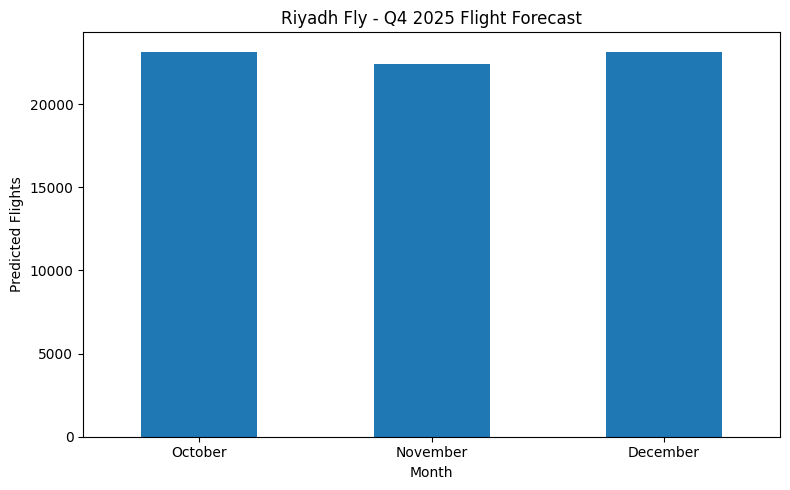

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load and prepare data
df = pd.read_csv("Riyadh_Fly_EDA_Cleaned.csv")
df["scheduled_date"] = pd.to_datetime(df["scheduled_date"])
daily = df.groupby("scheduled_date").size().asfreq("D", fill_value=0).rename("flights").reset_index()

# Create features
def features(d):
    d = pd.Series(pd.to_datetime(d))
    return pd.DataFrame({
        "day": (d - pd.Timestamp("2025-04-01")).dt.days,
        "weekday": d.dt.dayofweek,
        "month": d.dt.month
    })

# Train and test (last 30 days for testing)
split = daily["scheduled_date"].max() - pd.Timedelta(days=30)
train = daily["scheduled_date"] <= split
test = ~train

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(features(daily.loc[train, "scheduled_date"]), daily.loc[train, "flights"])
pred = model.predict(features(daily.loc[test, "scheduled_date"]))

print("MAE:", round(mean_absolute_error(daily.loc[test, "flights"], pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(daily.loc[test, "flights"], pred)), 2))

# Retrain on all data and predict Q4
model.fit(features(daily["scheduled_date"]), daily["flights"])
q4 = pd.date_range("2025-10-01", "2025-12-31")
forecast = pd.DataFrame({"date": q4, "predicted": model.predict(features(q4))})
forecast["predicted"] = forecast["predicted"].clip(lower=0).round().astype(int)

monthly = forecast.groupby(forecast["date"].dt.month)["predicted"].sum().reindex([10, 11, 12])
monthly.index = ["October", "November", "December"]

print("\nQ4 2025 Flight Forecast:")
print(monthly)
print("Q4 Total:", monthly.sum())

# Plot monthly forecast
monthly.plot(kind="bar", figsize=(8, 5), title="Riyadh Fly - Q4 2025 Flight Forecast",
             xlabel="Month", ylabel="Predicted Flights", rot=0)
plt.tight_layout()
plt.show()

### Q4 2025 Flight Prediction

A Random Forest Regressor was developed to predict the number of flights for October, November, and December 2025 using historical flight data from Q2 and Q3 2025. Flight records were aggregated into daily counts, and time-based features were created, including day, weekday, and month.

The model was evaluated using a chronological split, with the last 30 days reserved for testing. Performance was measured using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). After evaluation, the model was retrained on the full dataset to generate daily and monthly flight predictions for Q4 2025, which were visualized in a bar chart.

Predicted Top 5 Destinations — Q4 2025
destination_airport
Jeddah       12197
Dubai         5481
Cairo         4434
Abha          4057
Ad Dammam     3283
Name: count, dtype: int64


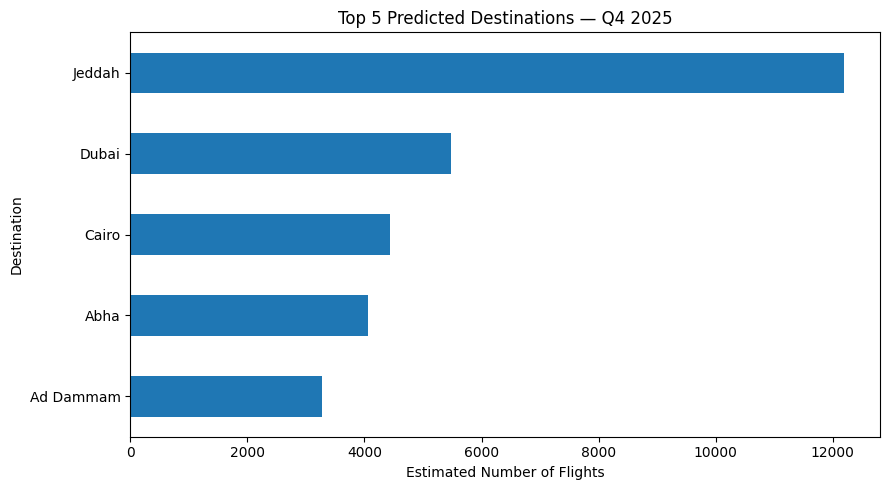

In [ ]:
df["scheduled_date"] = pd.to_datetime(df["scheduled_date"])

# Q2 and Q3 historical data
days = (df["scheduled_date"].max() - df["scheduled_date"].min()).days + 1
q4_days = 92  # October + November + December

# Estimate Q4 flights for each destination
top5 = (
    df["destination_airport"].value_counts()
    .head(5)
    .div(days)
    .mul(q4_days)
    .round()
    .astype(int)
    .sort_values()
)

print("Predicted Top 5 Destinations — Q4 2025")
print(top5.sort_values(ascending=False))

# Plot
top5.plot(kind="barh", figsize=(9, 5), title="Top 5 Predicted Destinations — Q4 2025")
plt.xlabel("Estimated Number of Flights")
plt.ylabel("Destination")
plt.tight_layout()
plt.show()

### Predicted Top 5 Destinations — Q4 2025

The predictions were calculated using historical flight data from Q2 and Q3 2025. For each destination, the total number of flights was divided by the number of days in the historical period to calculate the average daily flights. This average was then multiplied by the 92 days of Q4 to estimate the expected number of flights, assuming historical patterns remain consistent.

Predicted Most Active Airlines — Q4 2025
airline_name
Saudi Arabian    27053
flynas           15073
flyadeal         11051
Gulf Air           971
flydubai           906
EgyptAir           845
Qatar              793
Etihad             692
Emirates           596
Turkish            566
Name: count, dtype: int64


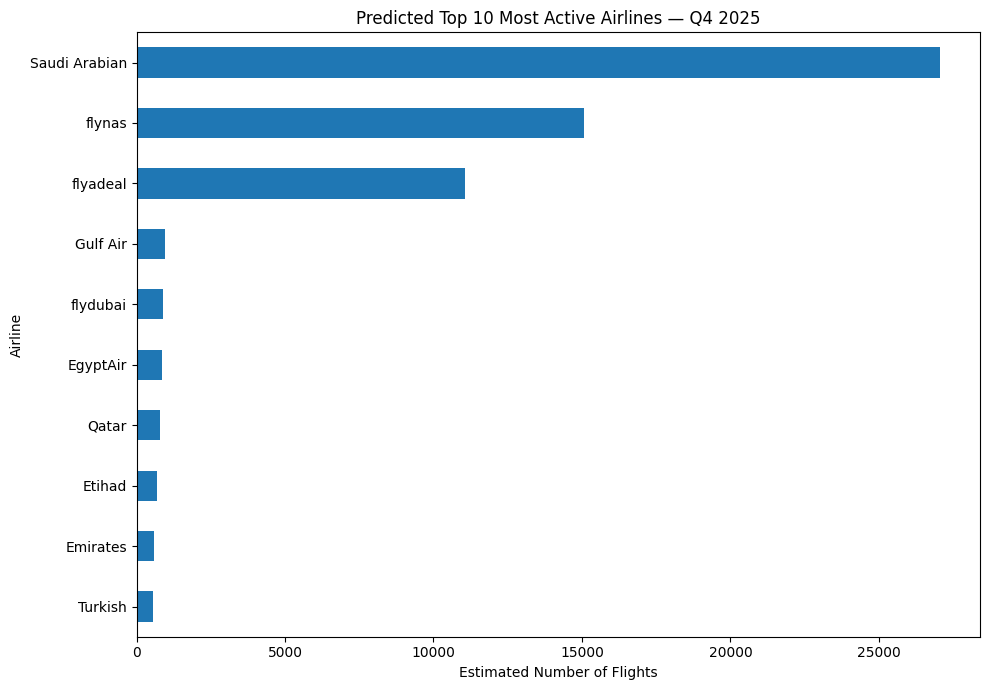

In [ ]:
days = (df["scheduled_date"].max() - df["scheduled_date"].min()).days + 1

top10 = (
    df["airline_name"].value_counts()
    .div(days)
    .mul(92)
    .round()
    .astype(int)
    .nlargest(10)
    .sort_values()
)

print("Predicted Most Active Airlines — Q4 2025")
print(top10.sort_values(ascending=False))

top10.plot(
    kind="barh",
    figsize=(10, 7),
    title="Predicted Top 10 Most Active Airlines — Q4 2025",
    xlabel="Estimated Number of Flights",
    ylabel="Airline"
)

plt.tight_layout()
plt.show()

### Predicted Most Active Airlines — Q4 2025

The predictions were calculated using historical flight data from Q2 and Q3 2025. For each airline, the total number of flights was divided by the number of days in the historical period to calculate the average daily flights. This average was then multiplied by the 92 days of Q4 to estimate the expected number of flights, assuming historical activity levels remain consistent.

MAE: 1.92
RMSE: 2.41

Predicted Busiest Hours — Q4 2025
scheduled_hour
20    3788
16    3563
19    3518
18    3475
23    3454
22    3420
21    3419
17    3274
10    3151
15    3063
Name: predicted_flights, dtype: int64


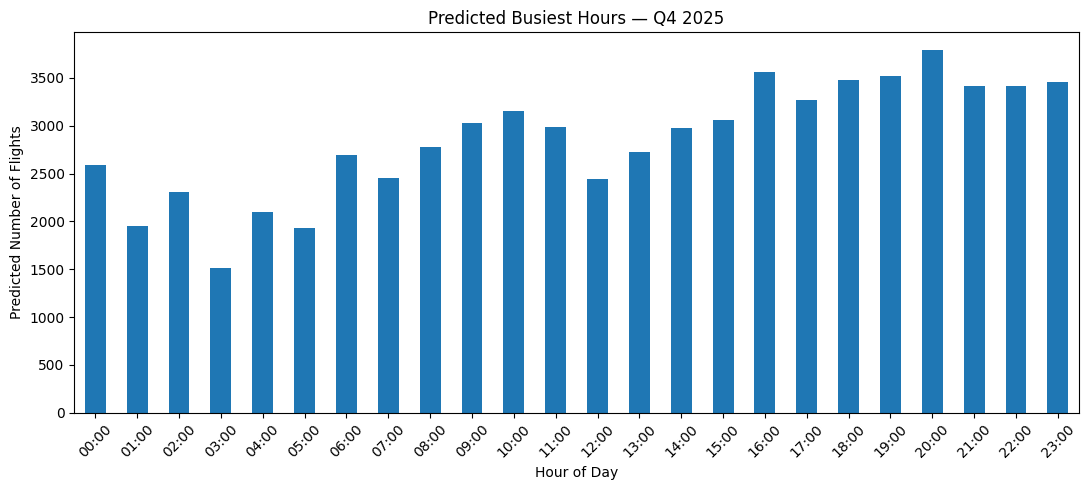

In [ ]:
df["scheduled_date"] = pd.to_datetime(df["scheduled_date"])
df["scheduled_hour"] = pd.to_datetime(
    df["scheduled_time"], format="mixed"
).dt.hour

# Count flights per day and hour
daily = df.groupby(["scheduled_date", "scheduled_hour"]).size().rename("flights")

idx = pd.MultiIndex.from_product(
    [pd.date_range(df["scheduled_date"].min(), df["scheduled_date"].max()), range(24)],
    names=["scheduled_date", "scheduled_hour"]
)
daily = daily.reindex(idx, fill_value=0).reset_index()

# Features
def features(d):
    dates = d["scheduled_date"]
    return pd.DataFrame({
        "hour": d["scheduled_hour"],
        "weekday": dates.dt.dayofweek,
        "month": dates.dt.month,
        "day_of_year": dates.dt.dayofyear
    })

# Train and test on the last 30 days
split = daily["scheduled_date"].max() - pd.Timedelta(days=30)
train = daily["scheduled_date"] <= split
test = ~train

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(features(daily[train]), daily.loc[train, "flights"])
pred = model.predict(features(daily[test]))

print("MAE:", round(mean_absolute_error(daily.loc[test, "flights"], pred), 2))
print("RMSE:", round(mean_squared_error(daily.loc[test, "flights"], pred) ** 0.5, 2))

# Predict Q4
model.fit(features(daily), daily["flights"])

q4_dates = pd.date_range("2025-10-01", "2025-12-31")
q4 = pd.MultiIndex.from_product(
    [q4_dates, range(24)],
    names=["scheduled_date", "scheduled_hour"]
).to_frame(index=False)

q4["predicted_flights"] = model.predict(features(q4)).clip(min=0)

hourly = q4.groupby("scheduled_hour")["predicted_flights"].sum().round().astype(int)

print("\nPredicted Busiest Hours — Q4 2025")
print(hourly.sort_values(ascending=False).head(10))

hourly.plot(kind="bar", figsize=(11, 5), title="Predicted Busiest Hours — Q4 2025")
plt.xlabel("Hour of Day")
plt.ylabel("Predicted Number of Flights")
plt.xticks(range(24), [f"{h:02d}:00" for h in range(24)], rotation=45)
plt.tight_layout()
plt.show()

### Predicted Busiest Hours — Q4 2025

A Random Forest Regressor was trained on historical flight data from Q2 and Q3 2025 to predict hourly flight activity during Q4. The model used time-based features, including hour of day, day of the week, and month. Its performance was evaluated using MAE (1.92) and RMSE (2.41) on a held-out test period. The predictions indicate that 20:00 is expected to be the busiest hour, assuming historical flight patterns remain consistent.

# **Conclusion**

This notebook provided valuable experience in cleaning, analyzing, and visualizing real-world flight data. Through EDA, I identified key patterns in flight activity, popular destinations, active airlines, and peak hours. The findings also supported the development of predictive models and an interactive Streamlit dashboard, transforming raw data into meaningful insights.